# Tumor Segmentation in MRI Volumes

### Loading Data

In [1]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("/l/users/faiz.ramadhan/brain_tumor/Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
split_df = pd.read_csv(SPLIT_FILE)

assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}

for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


## Inspect Data

In [2]:
from pathlib import Path
import nibabel as nib
import numpy as np

images_dir = DATA_ROOT / "imagesTr"
labels_dir = DATA_ROOT / "labelsTr"

# Get image cases
image_files = sorted(
    p for p in images_dir.glob("*.nii.gz")
    if not p.name.startswith("._")
)

# Load at least 3 cases
for image_path in image_files[:3]:
    case_id = image_path.name.replace(".nii.gz", "")
    label_path = labels_dir / f"{case_id}.nii.gz"

    image_nii = nib.load(image_path)
    label_nii = nib.load(label_path)

    image = image_nii.get_fdata()
    label = label_nii.get_fdata()

    print("=" * 80)
    print(f"CASE: {case_id}")
    print(f"Image shape: {image.shape}")
    print(f"Label shape: {label.shape}")

    print("\nAffine:")
    print(image_nii.affine)

    print("\nOrientation:")
    print(nib.aff2axcodes(image_nii.affine))

    print("\nVoxel spacing:")
    print(image_nii.header.get_zooms()[:3])

    print("\nLabel values:")
    print(np.unique(label))

CASE: BRATS_001
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]
CASE: BRATS_002
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]
CASE: BRATS_003
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]


Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Selected voxel: (np.int64(158), np.int64(109), np.int64(67))
Selected slice: 67
4


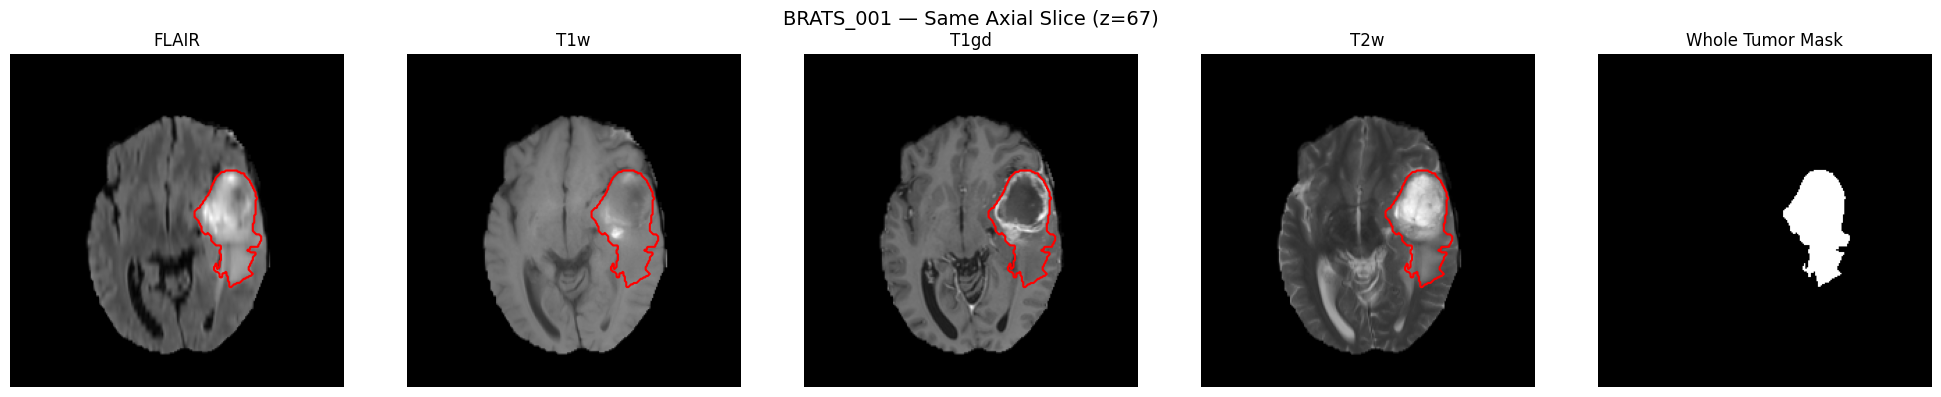

In [3]:
import matplotlib.pyplot as plt

case = "BRATS_001"

image_path = DATA_ROOT / "imagesTr" / f"{case}.nii.gz"
label_path = DATA_ROOT / "labelsTr" / f"{case}.nii.gz"

image_nii = nib.load(image_path)
label_nii = nib.load(label_path)

image = image_nii.get_fdata()
label = label_nii.get_fdata()

print("Image shape:", image.shape)
print("Label shape:", label.shape)


# Channel order from dataset.json
modalities = {
    "FLAIR": image[..., 0],
    "T1w":   image[..., 1],
    "T1gd":  image[..., 2],
    "T2w":   image[..., 3],
}


# Tumor mask
# 0 = background
# 1 = edema
# 2 = non-enhancing tumor
# 3 = enhancing tumor
#
# Whole tumor = labels 1 + 2 + 3

whole_tumor = (label > 0).astype(np.uint8)


# Find a slice containing tumor

tumor_voxels = np.argwhere(whole_tumor > 0)

# Take the middle tumor voxel
x, y, z = tumor_voxels[len(tumor_voxels) // 2]

print("Selected voxel:", (x, y, z))
print("Selected slice:", z)


# --------------------------------------------------
# Display
# --------------------------------------------------

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

print(len(modalities.values()))

for ax, (title, modality_image) in zip(axes[:4], modalities.items()):

    ax.imshow(
        modality_image[:, :, z].T,
        cmap="gray",
        origin="lower"
    )

    ax.contour(
        whole_tumor[:, :, z].T,
        levels=[0.5],
        linewidths=1.5,
        colors='red'
    )

    ax.set_title(title)
    ax.axis("off")

# Whole-tumor reference mask
axes[4].imshow(
    whole_tumor[:, :, z].T,
    cmap="gray",
    origin="lower"
)

axes[4].set_title("Whole Tumor Mask")
axes[4].axis("off")


plt.suptitle(
    f"{case} — Same Axial Slice (z={z})",
    fontsize=14
)

plt.tight_layout()
plt.show()

Selected voxel: (np.int64(158), np.int64(109), np.int64(67))


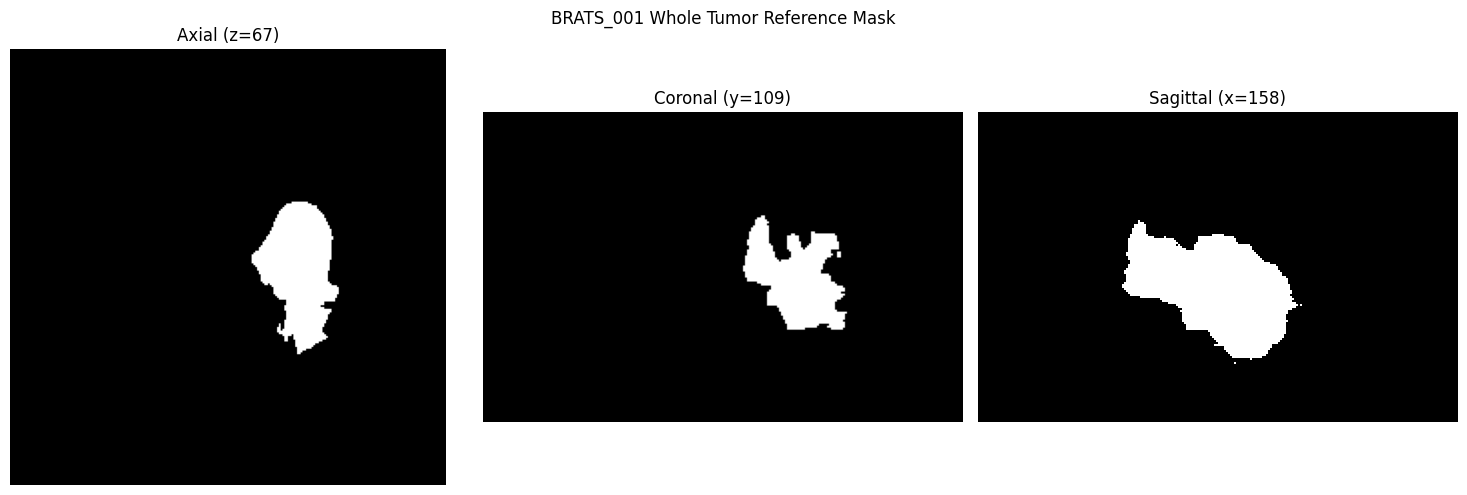

In [4]:
# Find center of tumor
tumor_voxels = np.argwhere(whole_tumor)
x, y, z = tumor_voxels[len(tumor_voxels) // 2]

print("Selected voxel:", (x, y, z))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Axial: XY plane
axes[0].imshow(
    whole_tumor[:, :, z].T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title(f"Axial (z={z})")

# Coronal: XZ plane
axes[1].imshow(
    whole_tumor[:, y, :].T,
    cmap="gray",
    origin="lower"
)
axes[1].set_title(f"Coronal (y={y})")

# Sagittal: YZ plane
axes[2].imshow(
    whole_tumor[x, :, :].T,
    cmap="gray",
    origin="lower"
)
axes[2].set_title(f"Sagittal (x={x})")

for ax in axes:
    ax.axis("off")

plt.suptitle("BRATS_001 Whole Tumor Reference Mask")
plt.tight_layout()
plt.show()

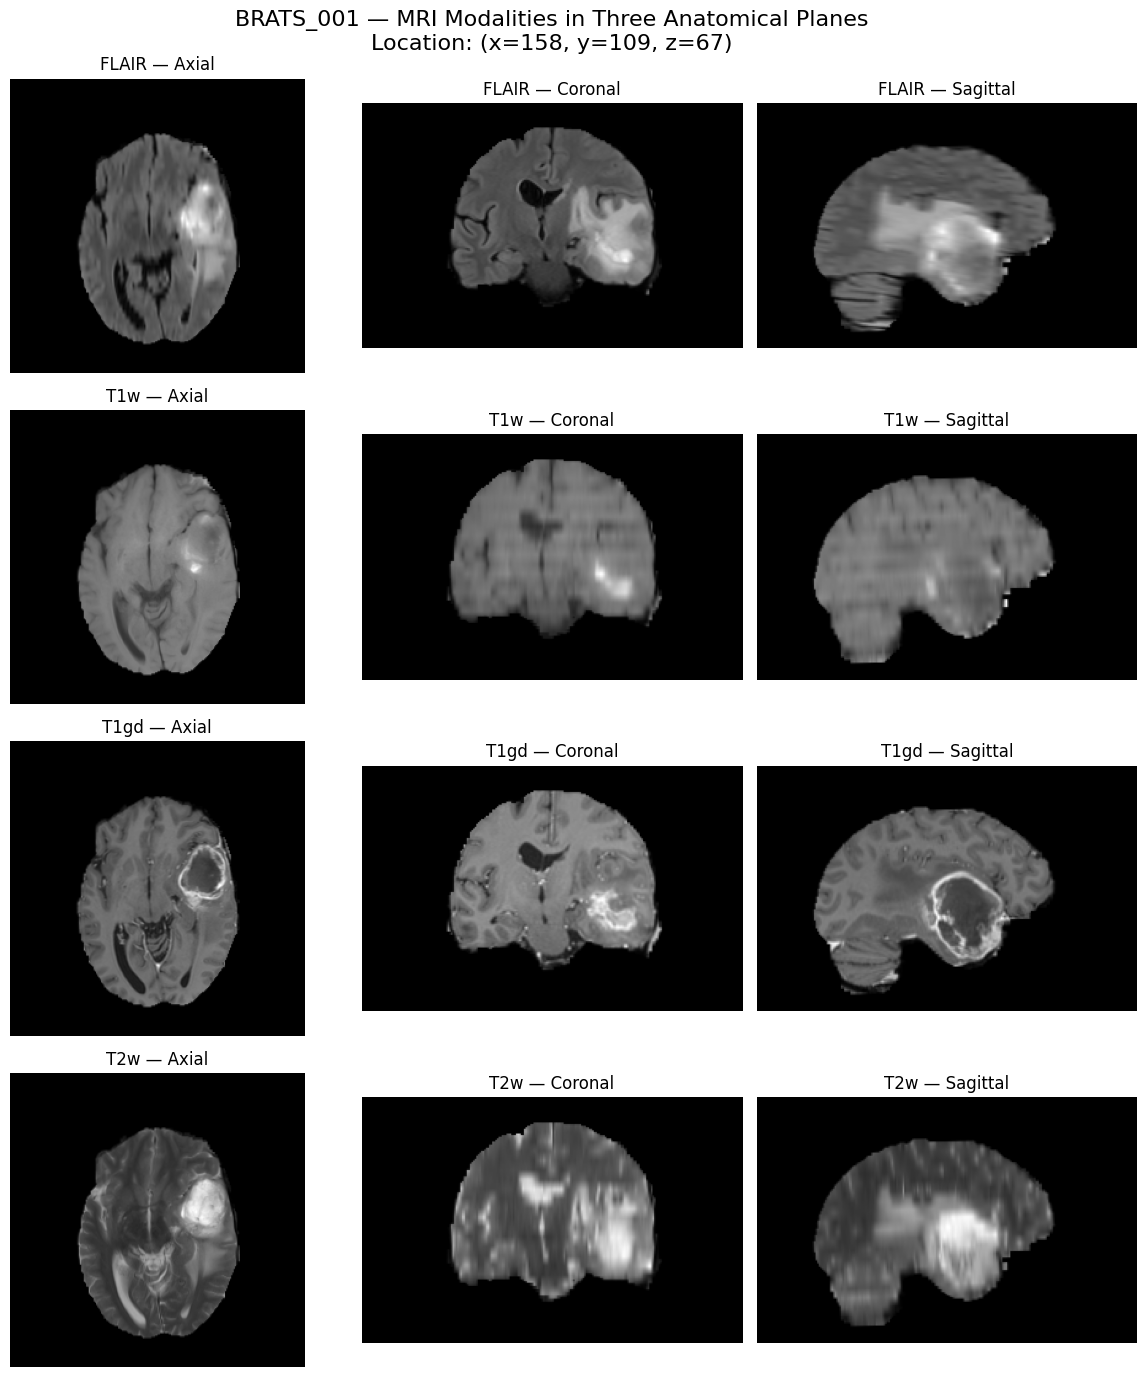

In [5]:
# --------------------------------------------------
# Plot: 4 rows × 3 columns
# --------------------------------------------------

fig, axes = plt.subplots(
    4, 3,
    figsize=(12, 14)
)

for row, (name, volume) in enumerate(modalities.items()):

    # Axial
    axes[row, 0].imshow(
        volume[:, :, z].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 0].set_title(f"{name} — Axial")

    # Coronal
    axes[row, 1].imshow(
        volume[:, y, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 1].set_title(f"{name} — Coronal")

    # Sagittal
    axes[row, 2].imshow(
        volume[x, :, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 2].set_title(f"{name} — Sagittal")

    for col in range(3):
        axes[row, col].axis("off")


plt.suptitle(
    f"BRATS_001 — MRI Modalities in Three Anatomical Planes\n"
    f"Location: (x={x}, y={y}, z={z})",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Data Split

In [6]:
split_df = pd.read_csv("assignment2_split.csv")
display(split_df)

display(split_df['split'].value_counts())

,case_id,split,image_relpath,label_relpath
0,BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz
1,BRATS_002,test,imagesTr/BRATS_002.nii.gz,labelsTr/BRATS_002.nii.gz
2,BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz
3,BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz
4,BRATS_005,train,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz
...,...,...,...,...
479,BRATS_480,train,imagesTr/BRATS_480.nii.gz,labelsTr/BRATS_480.nii.gz
480,BRATS_481,test,imagesTr/BRATS_481.nii.gz,labelsTr/BRATS_481.nii.gz
481,BRATS_482,test,imagesTr/BRATS_482.nii.gz,labelsTr/BRATS_482.nii.gz
482,BRATS_483,train,imagesTr/BRATS_483.nii.gz,labelsTr/BRATS_483.nii.gz


split
train         338
test           73
validation     73
Name: count, dtype: int64

In [7]:
def calculate_tumor_volume(label_relpath):
    """Calculate whole-tumor volume in mm³ from a reference mask."""

    label_path = DATA_ROOT / label_relpath

    label_nii = nib.load(label_path)
    label = label_nii.get_fdata()

    # Whole tumor = edema + non-enhancing tumor + enhancing tumor
    whole_tumor = label > 0

    # Voxel spacing in mm
    spacing = label_nii.header.get_zooms()[:3]

    # Volume of one voxel
    voxel_volume = np.prod(spacing)

    # Number of tumor voxels × volume per voxel
    tumor_volume_mm3 = np.sum(whole_tumor) * voxel_volume

    return tumor_volume_mm3

In [8]:
split_df['tumor_volume'] = split_df['label_relpath'].apply(lambda x: calculate_tumor_volume(x))
split_df.head()

,case_id,split,image_relpath,label_relpath,tumor_volume
0,BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz,111724.0
1,BRATS_002,test,imagesTr/BRATS_002.nii.gz,labelsTr/BRATS_002.nii.gz,63061.0
2,BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz,173927.0
3,BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz,120660.0
4,BRATS_005,train,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz,80680.0


In [9]:
train_df = split_df[split_df['split']=='train'].drop('split', axis=1)
val_df = split_df[split_df['split']=='validation'].drop('split', axis=1)
test_df = split_df[split_df['split']=='test'].drop('split', axis=1)

assert set(train_df['case_id']) & set(val_df['case_id']) != {}
assert set(test_df['case_id']) & set(val_df['case_id']) != {}
assert set(train_df['case_id']) & set(train_df['case_id']) != {}

print("No intersection in train, val, and test")

print(f"train: {len(train_df)}")
print(f"val: {len(val_df)}")
print(f"test: {len(test_df)}")

No intersection in train, val, and test
train: 338
val: 73
test: 73


Train


count       338.000000
mean     102964.050296
std       56960.257869
min        8478.000000
25%       60023.000000
50%       95484.500000
75%      143920.750000
max      265254.000000
Name: tumor_volume, dtype: float64

Val


count        73.000000
mean     100764.835616
std       62950.123009
min        7285.000000
25%       51853.000000
50%       91560.000000
75%      148062.000000
max      266936.000000
Name: tumor_volume, dtype: float64

<Axes: xlabel='tumor_volume', ylabel='Count'>

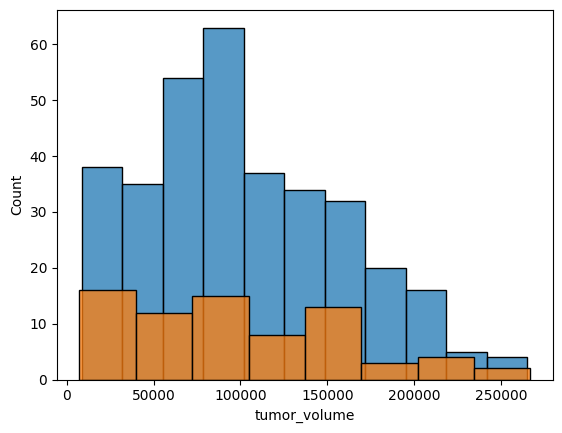

In [10]:
import seaborn as sns

print("Train")
display(train_df['tumor_volume'].describe())

print("Val")
display(val_df['tumor_volume'].describe())

sns.histplot(train_df['tumor_volume'])
sns.histplot(val_df['tumor_volume'])

## Preprocess

In [12]:
print(image.shape)
print(label.shape)

(240, 240, 155, 4)
(240, 240, 155)


In [ ]:
print(image.shape)
print(label.shape)

print("\nImage Voxel spacing:")
print(image_nii.header.get_zooms()[:3])
# because the number of pixel and the spacing is already the same, we dont need to resample it


Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))
